In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import AdaBoostRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

In [2]:

#import tensorflow as tf

In [3]:

#from tensorflow.keras.models import Sequential
#from tensorflow.keras.layers import Dense, Dropout
#from tensorflow.keras.optimizers import Adam
#from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [2]:
df_latitudes = pd.read_excel('../Datasets/College_latitudes.xlsx') #Done
df_rankings = pd.read_excel('../Datasets/College_rankings.xlsx') #Done
df_players = pd.read_excel('../Datasets/college_hockey_stats.xlsx')
df_goalies = pd.read_excel('../Datasets/college_hockey_goalie_stats.xlsx')
df_coaches = pd.read_excel('../Datasets/college_hockey_history.xlsx') #Done
df_conference_record = pd.read_excel('../Datasets/team_conference_record.xlsx') #Done
df_key = pd.read_excel('../Datasets/team_names_numbers.xlsx')

In [3]:
df_combined0 = df_rankings.merge(df_latitudes.drop(columns=['College']), on='Rk', how='inner')
df_combined0.head(10)

,Rk,Team,Category,Rank,Latitude
0,1,Air-Force,NL,8,39.0100
1,4,Alaska,N,388,64.8591
2,3,Alaska-Anchorage,R,78,61.1897
3,5,American-Intl,N,392,42.1035
4,61,Arizona-State,N,121,33.4242
5,6,Army,NL,8,41.3917
6,64,Augustana,NL,100,43.5455
7,7,Bemidji-State,R,91,47.4769
8,8,Bentley,R,2,42.3750
9,9,Boston-College,N,37,42.3369


In [4]:
df_combined0['Category'] = df_combined0['Category'].replace("R", "2").replace("NL", "1").replace("N", "0").replace("'", "")

Get coaches tenure

In [5]:
df_coaches_filtered = df_coaches[['Team Number', 'Coach', 'Season']].rename(columns={'Team Number': 'Rk'})
df_coaches_filtered = df_coaches_filtered.dropna()
df_coaches_filtered['StartYear'] = df_coaches_filtered['Season'].str[:4].astype(int)
df_coaches_filtered.sort_values(['Rk', 'Coach', 'StartYear'], inplace=True)

In [6]:
def compute_tenure(group):
    tenure = []
    prev_year = None
    current = 0
    for year in group['StartYear']:
        # If not consecutive, reset tenure to 0
        if prev_year is None or year != prev_year + 1:
            current = 0
        else:
            current += 1
        tenure.append(current)
        prev_year = year
    group['tenure'] = tenure
    return group

In [7]:
# Apply the function per team and coach
df_coaches_filtered = df_coaches_filtered.groupby(['Rk', 'Coach'], group_keys=False).apply(compute_tenure)

/var/folders/nr/252791g92619jw78hvgkc57h0000gn/T/ipykernel_41361/1387790384.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_coaches_filtered = df_coaches_filtered.groupby(['Rk', 'Coach'], group_keys=False).apply(compute_tenure)


In [8]:
df_coaches_filtered

,Rk,Coach,Season,StartYear,tenure
39,1,Chuck Delich,1985‑86,1985,0
38,1,Chuck Delich,1986‑87,1986,1
37,1,Chuck Delich,1987‑88,1987,2
36,1,Chuck Delich,1988‑89,1988,3
35,1,Chuck Delich,1989‑90,1989,4
...,...,...,...,...,...
3943,422,David Borges,2022‑23,2022,0
3942,422,David Borges,2023‑24,2023,1
1865,433,Bill Muckalt,2024‑25,2024,0
1867,433,Rick Zombo,2022‑23,2022,0


In [9]:

# Drop the helper column
df_coaches_filtered.drop(columns=['Coach'], inplace=True)

Join on Key then get aggrigate of team records

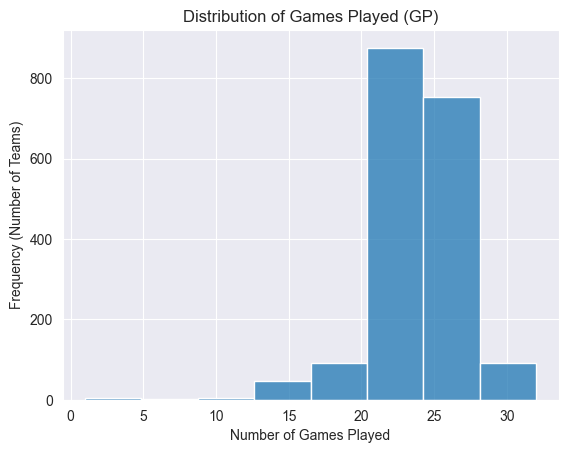

In [10]:
sns.histplot(data=df_conference_record, x='GP', bins=8, kde=False)
# - data: specifies the DataFrame
# - x: specifies the column for the histogram axis
# - bins: controls the number of bars (optional, seaborn can choose automatically)
# - kde: Set to True if you want a Kernel Density Estimate line overlaid

# Add title and labels using Matplotlib functions
plt.title('Distribution of Games Played (GP)')
plt.xlabel('Number of Games Played')
plt.ylabel('Frequency (Number of Teams)')

# Show the plot
plt.show()

In [11]:
def clean_team_name(team_name):
    return team_name.replace(" ", "").replace(".", "").replace("-", "").replace("'", "")

df_conference_record['Team'] = df_conference_record['Team'].apply(clean_team_name)
df_key['Team'] = df_key['Team'].apply(clean_team_name)

df_conference_record_keyed = df_conference_record.merge(df_key, on='Team', how='left')

In [12]:
df_conference_record_keyed.head()

,Team,Season,GP,W,L,T,G,GA,Shots,G/G,...,PIM,PPG,PPo,PP%,oPPG,oPPo,PK%,SHG,oSHG,Rk
0,MinnesotaDuluth,2011-12,28,16,7,5,103,73,997.0,3.7,...,401.0,29.0,134.0,21.6,31.0,124.0,75.0,1.0,1.0,36.0
1,BostonUniversity,2011-12,27,17,9,1,101,70,839.0,3.7,...,536.0,36.0,140.0,25.7,22.0,156.0,85.9,5.0,0.0,10.0
2,BostonCollege,2011-12,27,19,7,1,96,60,812.0,3.6,...,382.0,27.0,119.0,22.7,16.0,124.0,87.1,7.0,4.0,9.0
3,Denver,2011-12,28,16,8,4,96,79,869.0,3.4,...,446.0,28.0,116.0,24.1,24.0,126.0,81.0,3.0,2.0,20.0
4,ColoradoCollege,2011-12,28,15,12,1,95,86,865.0,3.4,...,356.0,29.0,121.0,24.0,26.0,104.0,75.0,4.0,9.0,16.0


In [13]:
df_conference_record_keyed['PPG'] = ((df_conference_record_keyed['W']*2.0)+(df_conference_record_keyed['T']))/(df_conference_record_keyed['GP'])

In [14]:
df_ppg = df_conference_record_keyed[['Rk', 'PPG', 'Season']]
df_ppg = df_ppg.dropna()

In here add code to get the average record of the team under a specific coach

In [15]:
df_ppg['Rk'] = df_ppg['Rk'].astype(int)

In [18]:
# df_coaches_filtered.to_excel("../Processed_Datasets/coaches.xlsx", index=False)

In [16]:
df_ppg["Season"] = df_ppg["Season"].astype(str).str[:4].astype(int)
df_coaches_filtered["Season"] = df_coaches_filtered["Season"].astype(str).str[:4].astype(int)

In [17]:
df_combined1 = df_ppg.merge(df_coaches_filtered, on=['Rk', 'Season'], how='left')
df_combined1 = df_combined1.merge(df_combined0, on=['Rk'], how='left')
df_combined1.head(10)

,Rk,PPG,Season,StartYear,tenure,Team,Category,Rank,Latitude
0,36,1.321429,2011,2011,11,Minnesota-Duluth,2,20,46.8185
1,10,1.296296,2011,2011,38,Boston-University,0,41,42.3505
2,9,1.444444,2011,2011,17,Boston-College,0,37,42.3369
3,20,1.285714,2011,2011,17,Denver,0,121,39.6766
4,16,1.107143,2011,2011,12,Colorado-College,1,29,38.8462
5,23,1.259259,2011,2011,14,Holy-Cross,1,28,42.2385
6,25,1.185185,2011,2011,10,Maine,0,259,44.8842
7,26,1.296296,2011,2011,0,Mass-Lowell,0,152,42.6598
8,34,1.428571,2011,2011,12,Minnesota,0,54,44.9738
9,52,1.000000,2011,2011,6,St-Cloud-State,2,98,45.5539


For all Players Mark a 1 for players who are active on the same team for the next season

In [18]:

# Ensure the DataFrame is sorted by team (Rk) and season
df_combined1 = df_combined1.sort_values(['Rk', 'Season'])

# Create a helper column to identify each coaching stint within a team.
# A new stint is started whenever Tenure equals 0.
df_combined1['stint'] = df_combined1.groupby('Rk')['tenure'].apply(lambda x: (x == 0).cumsum())

# Step 1: For coaching stints (rows with Tenure != 0), compute the rolling average using prior seasons in that stint.
def compute_stint_avg(group):
    # Calculate cumulative sum and count of PPG within the stint, shifting by one to exclude the current season.
    group['cumsum'] = group['PPG'].cumsum().shift(1)
    group['cumcount'] = group['PPG'].expanding().count().shift(1)
    group['coach_ppg'] = group['cumsum'] / group['cumcount']
    return group

df_combined1 = df_combined1.groupby(['Rk', 'stint']).apply(compute_stint_avg)

# Step 2: For the first season of a coaching stint (Tenure==0), use the team’s historical PPG prior to that season.
# Compute overall cumulative sum and count for each team (across all seasons),
# then shift by one so that for each row we only include seasons before it.
df_combined1['team_cumsum'] = df_combined1.groupby('Rk')['PPG'].cumsum().shift(1)
df_combined1['team_cumcount'] = df_combined1.groupby('Rk')['PPG'].cumcount()  # cumcount gives previous count (0-indexed)

# For rows where Tenure equals 0 (i.e. first season of a new coaching stint),
# update coach_ppg using the overall historical average calculated from prior seasons.
mask_first = df_combined1['tenure'] == 0
df_combined1.loc[mask_first, 'coach_ppg'] = df_combined1.loc[mask_first, 'team_cumsum'] / df_combined1.loc[mask_first, 'team_cumcount']



TypeError: incompatible index of inserted column with frame index

In [19]:

# Remove helper columns if they are no longer needed.
df_combined1.drop(columns=['stint', 'cumsum', 'cumcount', 'team_cumsum', 'team_cumcount', 'StartYear'], inplace=True)

KeyError: "['stint', 'cumsum', 'cumcount', 'team_cumsum', 'team_cumcount'] not found in axis"

In [20]:
df_players["Season"] = df_players["Season"].astype(str).str[:4].astype(int)
df_goalies["Season"] = df_goalies["Season"].astype(str).str[:4].astype(int)

In [21]:
df_players.sort_values(by=['Rk', 'Season'], inplace=True)

# Create the next season column
next_season = df_players.copy()
next_season['Season'] -= 1
next_season = next_season.rename(columns={'Player': 'Next_Season_Player'})

# Merge to check for presence in next season
df_players = df_players.merge(next_season[['Rk', 'Season', 'Next_Season_Player']],
                              left_on=['Rk', 'Season', 'Player'],
                              right_on=['Rk', 'Season', 'Next_Season_Player'],
                              how='left')

df_players['Returning_Next_Season'] = df_players['Next_Season_Player'].notna().astype(int)

# Drop helper column
df_players.drop(columns=['Next_Season_Player'], inplace=True)


In [22]:
df_goalies.sort_values(by=['Rk', 'Season'], inplace=True)

# Create the next season column
next_season_goalies = df_goalies.copy()
next_season_goalies['Season'] -= 1
next_season_goalies = next_season_goalies.rename(columns={'Player': 'Next_Season_Player'})

# Merge to check for presence in next season
df_goalies = df_goalies.merge(next_season_goalies[['Rk', 'Season', 'Next_Season_Player']],
                              left_on=['Rk', 'Season', 'Player'],
                              right_on=['Rk', 'Season', 'Next_Season_Player'],
                              how='left')



In [23]:
df_goalies['Min'] = df_goalies['Min'].astype(str)
split_time = df_goalies['Min'].str.split(':', expand=True)
minutes = pd.to_numeric(split_time[0], errors='coerce')
seconds = pd.to_numeric(split_time[1], errors='coerce')

seconds = seconds.where((seconds >= 0) & (seconds < 60), np.nan)

df_goalies['Min_Decimal'] = minutes + seconds / 60.0

In [24]:
df_goalies['Returning_Next_Season'] = df_goalies['Next_Season_Player'].notna().astype(int)

# Drop helper column
df_goalies.drop(columns=['Next_Season_Player'], inplace=True)


In [25]:
df_goalies.head(10)

,Player,Team,Season,GP,W,L,T,GA,SA,Sv,SO,A,GAA,SV%,Min,Rk,Min_Decimal,Returning_Next_Season
0,Jason Torf,Air-Force,2011,11,6,3,2,14,261,247,4,0,1.26,0.946,667:58,1,667.966667,1
1,Stephen Caple,Air-Force,2011,16,9,3,4,35,375,340,1,0,2.19,0.907,960:40,1,960.666667,0
2,Paul Moberg,Air-Force,2011,1,0,0,0,1,7,6,0,0,4.11,0.857,14:36,1,14.600000,0
3,David Bosner,Air-Force,2012,1,0,0,0,0,2,2,0,0,0.00,1.000,6:41,1,6.683333,0
4,Jason Torf,Air-Force,2012,27,15,7,5,56,769,713,2,1,2.06,0.927,1632:01,1,1632.016667,1
5,Chris Truehl,Air-Force,2013,13,8,3,0,24,299,275,3,0,2.05,0.920,702:53,1,702.883333,1
6,Jason Torf,Air-Force,2013,14,7,4,3,36,419,383,1,0,2.63,0.914,822:17,1,822.283333,0
7,Paul Moberg,Air-Force,2013,3,0,2,0,7,34,27,0,0,4.29,0.794,97:59,1,97.983333,0
8,Chris Truehl,Air-Force,2014,23,10,9,3,60,570,510,0,0,2.85,0.895,1264:16,1,1264.266667,0
9,Connor Girard,Air-Force,2014,9,3,3,0,20,182,162,0,0,2.79,0.890,429:27,1,429.450000,0


In [26]:
df_goalies.columns

Index(['Player', 'Team', 'Season', 'GP', 'W', 'L', 'T', 'GA', 'SA', 'Sv', 'SO',
       'A', 'GAA', 'SV%', 'Min', 'Rk', 'Min_Decimal', 'Returning_Next_Season'],
      dtype='object')

Dropping columns Pts, Sh%, and FO% as these are all derived from other columns in the table

In [27]:
df_filtered = df_players.drop(columns=['Pts', 'Sh%', 'FO%'])
df_filtered = df_filtered.rename(columns={'PPG': 'power_play_goals'})

In [28]:
df_filtered_goalies = df_goalies.drop(columns=['GP', 'W', 'T', 'L', 'SA', 'GAA', 'SV%', 'A'])

In [29]:
df_returning_pct = df_filtered.groupby(['Rk', 'Season'])['Returning_Next_Season'].mean().reset_index()
df_returning_pct = df_returning_pct.rename(columns={'Returning_Next_Season': 'Percent_Returning'})

In [30]:
df_merged = pd.merge(df_ppg, df_returning_pct, on=['Rk', 'Season'], how='inner')
df_plot_filtered = df_merged[df_merged['Percent_Returning'] > 0].copy()

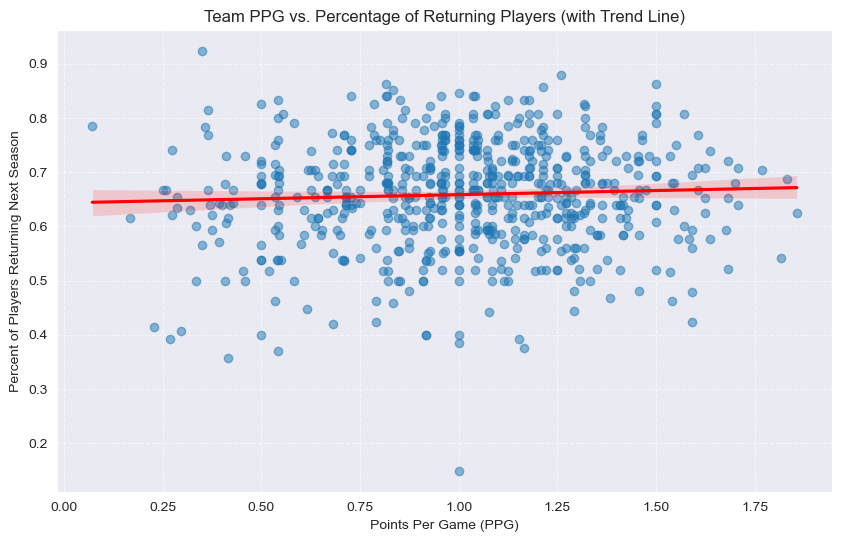

In [34]:
plt.figure(figsize=(10, 6)) # Adjust figure size as needed

# Use regplot to create scatter plot and add a linear regression line
sns.regplot(
    data=df_plot_filtered,
    x='PPG',
    y='Percent_Returning',
    scatter_kws={'alpha': 0.5}, # Set transparency for scatter points (0.0=invisible, 1.0=opaque)
    line_kws={'color': 'red'}     # Optional: Customize the line color
)

plt.xlabel('Points Per Game (PPG)')
plt.ylabel('Percent of Players Returning Next Season')
plt.title('Team PPG vs. Percentage of Returning Players (with Trend Line)')
plt.grid(True, linestyle='--', alpha=0.6) # Optional: slightly transparent grid
plt.show()

In [35]:
df_returning = df_filtered[df_filtered['Returning_Next_Season'] == 1].drop(columns=['Returning_Next_Season'])
df_returning_goalies = df_filtered_goalies[df_filtered_goalies['Returning_Next_Season'] == 1].drop(columns=['Returning_Next_Season'])

# Group by 'Team' and 'Season' and sum the numeric columns
df_players_summed = df_returning.groupby(['Rk', 'Season']).sum(numeric_only=True).reset_index()
df_goalies_summed = df_returning_goalies.groupby(['Rk', 'Season']).sum(numeric_only=True).reset_index()


df_players_summed.head()

,Rk,Season,GP,G,A,PIM,Shots,+/-,power_play_goals,SHG,GWG,Blk,FOW,FOL
0,1,2011,410,65,101,178,664,107,11,2,10,0.0,0.0,0.0
1,1,2012,344,59,102,187,610,80,16,1,10,167.0,603.0,534.0
2,1,2013,295,49,96,161,572,19,13,1,10,172.0,502.0,438.0
3,1,2014,297,41,82,139,444,-15,12,1,5,184.0,506.0,496.0
4,1,2015,434,72,114,177,674,103,10,4,13,306.0,616.0,625.0


In [36]:
df_all_players = df_players_summed.merge(df_goalies_summed, on=['Rk', 'Season'], how='left')
df_all_players.head(10)

,Rk,Season,GP,G,A,PIM,Shots,+/-,power_play_goals,SHG,GWG,Blk,FOW,FOL,GA,Sv,SO,Min_Decimal
0,1,2011,410,65,101,178,664,107,11,2,10,0.0,0.0,0.0,14.0,247.0,4.0,667.966667
1,1,2012,344,59,102,187,610,80,16,1,10,167.0,603.0,534.0,56.0,713.0,2.0,1632.016667
2,1,2013,295,49,96,161,572,19,13,1,10,172.0,502.0,438.0,24.0,275.0,3.0,702.883333
3,1,2014,297,41,82,139,444,-15,12,1,5,184.0,506.0,496.0,NaN,NaN,NaN,NaN
4,1,2015,434,72,114,177,674,103,10,4,13,306.0,616.0,625.0,56.0,624.0,4.0,1682.466667
5,1,2016,399,71,132,279,723,90,22,4,14,287.0,692.0,528.0,5.0,50.0,0.0,162.783333
6,1,2017,365,51,70,184,482,48,10,1,8,171.0,721.0,653.0,60.0,647.0,3.0,1682.633333
7,1,2018,330,33,62,188,462,-34,9,0,7,196.0,450.0,413.0,12.0,73.0,0.0,239.150000
8,1,2019,347,37,70,137,483,-1,8,0,5,232.0,177.0,208.0,68.0,612.0,2.0,1695.333333
9,1,2020,152,19,34,76,216,-21,5,1,2,61.0,198.0,227.0,33.0,178.0,0.0,433.266667


In [37]:
df_all_players

,Rk,Season,GP,G,A,PIM,Shots,+/-,power_play_goals,SHG,GWG,Blk,FOW,FOL,GA,Sv,SO,Min_Decimal
0,1,2011,410,65,101,178,664,107,11,2,10,0.0,0.0,0.0,14.0,247.0,4.0,667.966667
1,1,2012,344,59,102,187,610,80,16,1,10,167.0,603.0,534.0,56.0,713.0,2.0,1632.016667
2,1,2013,295,49,96,161,572,19,13,1,10,172.0,502.0,438.0,24.0,275.0,3.0,702.883333
3,1,2014,297,41,82,139,444,-15,12,1,5,184.0,506.0,496.0,NaN,NaN,NaN,NaN
4,1,2015,434,72,114,177,674,103,10,4,13,306.0,616.0,625.0,56.0,624.0,4.0,1682.466667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
654,60,2022,301,32,71,103,533,4,5,0,3,194.0,280.0,269.0,70.0,617.0,2.0,1434.250000
655,60,2023,299,46,70,192,516,-75,11,0,6,184.0,292.0,383.0,NaN,NaN,NaN,NaN
656,63,2021,239,22,40,110,282,-134,6,1,2,191.0,438.0,583.0,0.0,1.0,0.0,3.216667
657,63,2022,346,51,79,153,489,-47,17,2,7,180.0,671.0,657.0,67.0,671.0,1.0,1448.550000


In [38]:
columns_to_fill = ['GA', 'Sv', 'SO', 'Min_Decimal']
df_all_players[columns_to_fill] = df_all_players[columns_to_fill].fillna(0)

In [39]:
df_combined2 = df_combined1.merge(df_all_players, on=['Rk', 'Season'], how='left')

In [40]:
df_combined2['Category'] = df_combined2['Category'].astype(int)

In [41]:
df_combined2_seasons = df_combined2[(df_combined2['Season'] > 2012) & (df_combined2['Season'] < 2024)]

In [42]:
df_combined2_seasons[['G', 'Shots', 'GA', 'Min_Decimal']].rename(columns={
    'G': 'Goals',
    'GA': 'Goals Against',
    'Min_Decimal': 'Goalie_Minutes'
}).describe()


,Goals,Shots,Goals Against,Goalie_Minutes
count,556.000000,556.000000,556.000000,556.000000
mean,43.539568,467.253597,35.258993,808.370504
std,14.342159,118.898406,27.633858,610.044586
min,0.000000,19.000000,0.000000,0.000000
25%,34.000000,385.750000,5.000000,92.858333
50%,42.000000,455.500000,38.000000,905.291667
75%,52.000000,539.250000,57.000000,1350.395833
max,95.000000,874.000000,103.000000,1726.200000


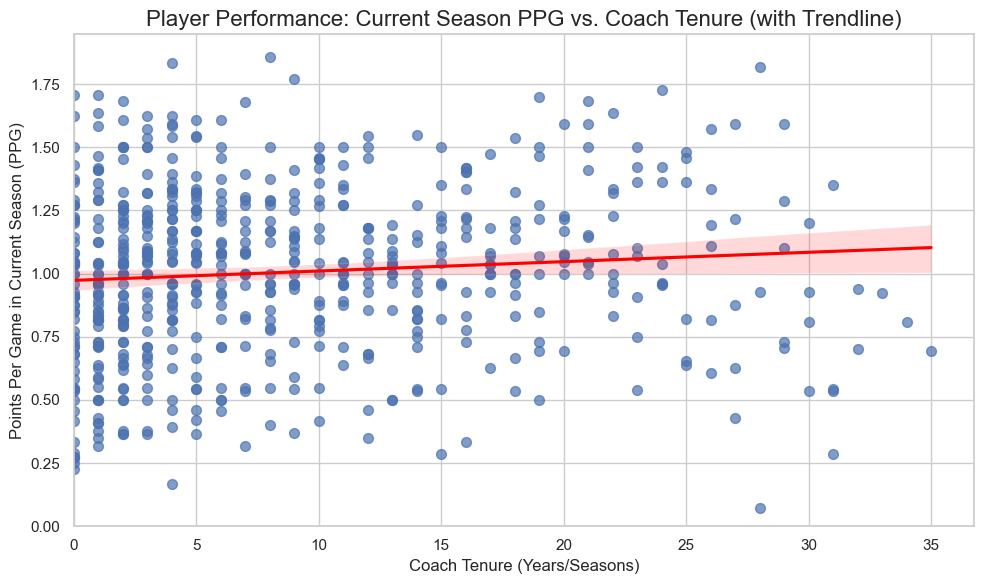

In [43]:
sns.set_theme(style="whitegrid")

# Create the scatter plot with a regression line using regplot
plt.figure(figsize=(10, 6)) # Adjust figure size as needed

# Using regplot combines scatter plot and linear regression line
# Plotting 'tenure' on x-axis now
reg_plot = sns.regplot(
    data=df_combined2_seasons,
    x='tenure', # Changed from 'G' to 'tenure'
    y='PPG',
    # Optional: customize the line/scatter appearance
    scatter_kws={'s': 50, 'alpha': 0.7}, # Pass arguments to underlying plt.scatter
    line_kws={'color': 'red'} # Changed color for variety, Pass arguments to underlying plt.plot for the line
    # ci=None # Uncomment this to hide the confidence interval ribbon around the line
)

# Add informative title and labels (Updated for new variables)
plt.title('Player Performance: Current Season PPG vs. Coach Tenure (with Trendline)', fontsize=16)
plt.xlabel('Coach Tenure (Years/Seasons)', fontsize=12) # Updated x-axis label
plt.ylabel('Points Per Game in Current Season (PPG)', fontsize=12)

# Set the axis limits to start at 0
plt.xlim(left=0)
plt.ylim(bottom=0)

# Ensure plot is displayed
plt.tight_layout() # Adjusts plot to prevent labels overlapping
plt.show()

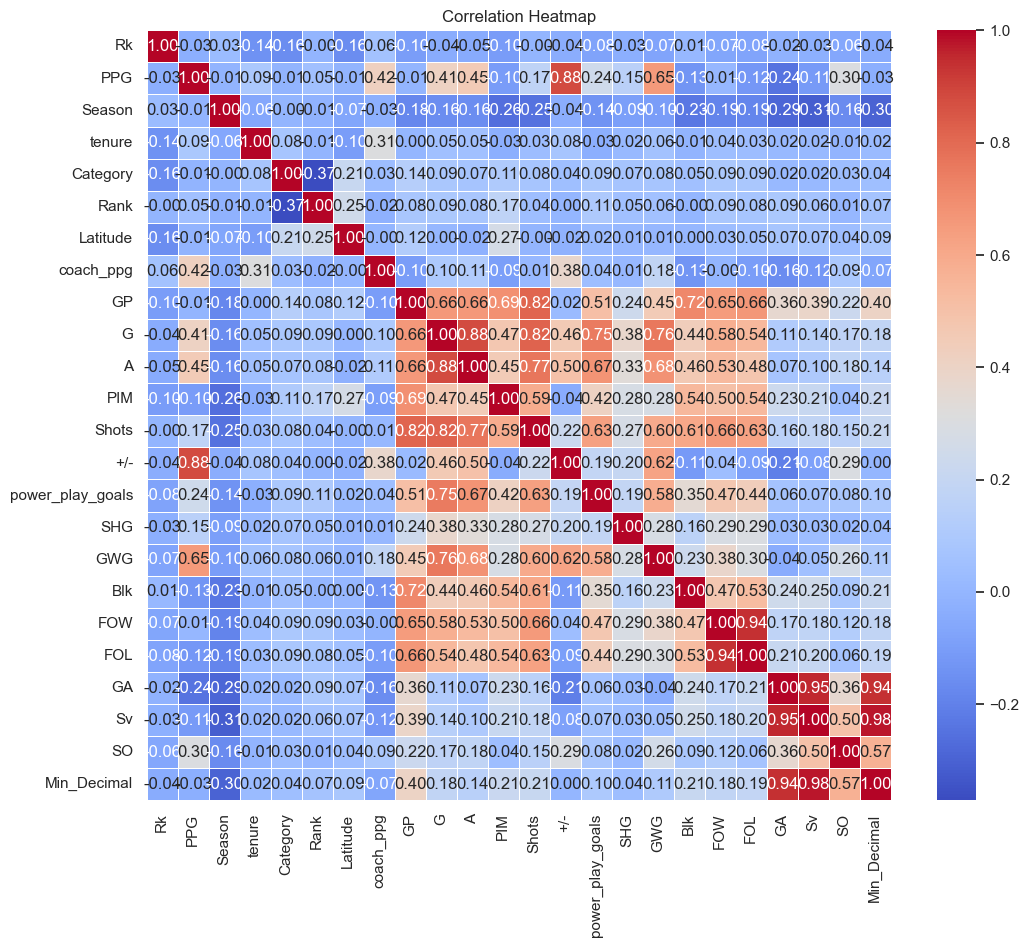

In [44]:
def create_correlation_heatmap(df):
    """
    Creates and displays a correlation heatmap for a given DataFrame.

    Args:
        df (pd.DataFrame): The DataFrame for which to create the heatmap.
    """
    correlation_matrix = df.corr()
    plt.figure(figsize=(12, 10))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
    plt.title('Correlation Heatmap')
    plt.show()

# Example usage (replace 'df_combined2_seasons.csv' with your file path):
create_correlation_heatmap(df_combined2_seasons)

In [45]:
category_mapping = {
    0: 'National',
    1: 'National Liberal Arts',
    2: 'Regional'
}

# 2. Apply the mapping to the 'Category' column.
#    This replaces the numbers 0, 1, 2 with the corresponding strings.
#    Note: This modifies the DataFrame in place. If you want to keep the original
#    numeric column, you could create a new column instead, like:
#    df_combined2_seasons['Category_Label'] = df_combined2_seasons['Category'].map(category_mapping)
#    And then use x='Category_Label' in the plot command.
df_combined2_seasons['Category_temp'] = df_combined2_seasons['Category'].map(category_mapping)

/var/folders/nr/252791g92619jw78hvgkc57h0000gn/T/ipykernel_94393/3512843519.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_combined2_seasons['Category_temp'] = df_combined2_seasons['Category'].map(category_mapping)


In [46]:
df_combined2_seasons['Category_temp'].unique()

array(['National Liberal Arts', 'Regional', 'National'], dtype=object)

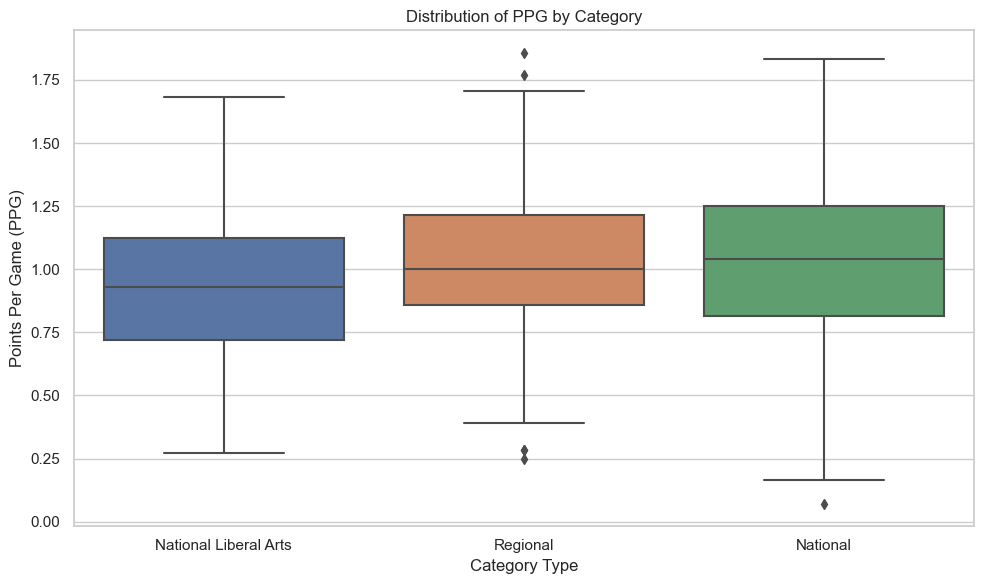

In [47]:

# 3. Check if all categories were mapped correctly (optional but good practice)

# 4. Create the box plot using Seaborn
plt.figure(figsize=(10, 6)) # Adjust figure size for better readability
sns.boxplot(data=df_combined2_seasons, x='Category_temp', y='PPG')

# 5. Add titles and labels for clarity
plt.title('Distribution of PPG by Category')
plt.xlabel('Category Type')
plt.ylabel('Points Per Game (PPG)')

# 6. Ensure layout is neat (prevents labels from overlapping)
plt.tight_layout()

# 7. Display the plot
plt.show()

In [48]:
df_combined2_seasons = df_combined2_seasons.drop(columns=['Category_temp'])

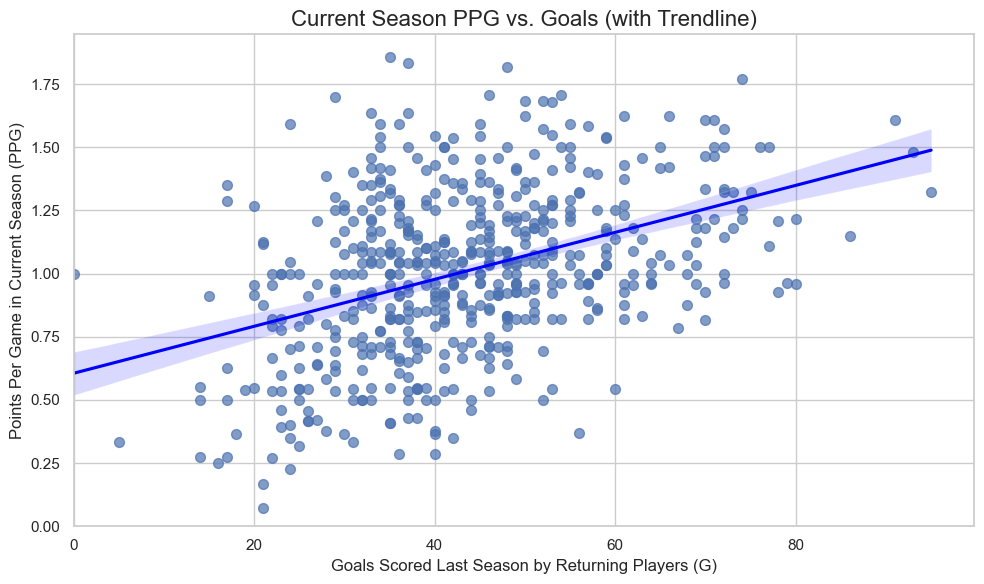

In [49]:


# Set the aesthetic style of the plots
sns.set_theme(style="whitegrid")

# Create the scatter plot with a regression line using regplot
plt.figure(figsize=(10, 6)) # Adjust figure size as needed

# Using regplot combines scatter plot and linear regression line
# Plotting 'G' on x-axis now
reg_plot = sns.regplot(
    data=df_combined2_seasons,
    x='G',     # Changed from 'tenure' to 'G' (Goals)
    y='PPG',   # y-axis remains PPG
    # Optional: customize the line/scatter appearance
    scatter_kws={'s': 50, 'alpha': 0.7}, # Arguments for the scatter points
    line_kws={'color': 'blue'}          # Arguments for the regression line (changed color)
    # ci=None # Uncomment this to hide the confidence interval ribbon
)

# Add informative title and labels (Updated for new variables)
plt.title('Current Season PPG vs. Goals (with Trendline)', fontsize=16)
plt.xlabel('Goals Scored Last Season by Returning Players (G)', fontsize=12) # Updated x-axis label
plt.ylabel('Points Per Game in Current Season (PPG)', fontsize=12) # y-axis label remains appropriate

# Set the axis limits to start at 0 (often makes sense for Goals and PPG)
plt.xlim(left=0)
plt.ylim(bottom=0)

# Ensure plot is displayed neatly
plt.tight_layout() # Adjusts plot to prevent labels overlapping
plt.show()

In [50]:
df_combined2_seasons

,Rk,PPG,Season,tenure,Team,Category,Rank,Latitude,coach_ppg,GP,...,power_play_goals,SHG,GWG,Blk,FOW,FOL,GA,Sv,SO,Min_Decimal
14,1,1.222222,2013,16,Air-Force,1,8,39.0100,0.956179,295.0,...,13.0,1.0,10.0,172.0,502.0,438.0,24.0,275.0,3.0,702.883333
15,1,1.035714,2014,17,Air-Force,1,8,39.0100,0.973915,297.0,...,12.0,1.0,5.0,184.0,506.0,496.0,0.0,0.0,0.0,0.000000
16,1,1.321429,2015,18,Air-Force,1,8,39.0100,0.977778,434.0,...,10.0,4.0,13.0,306.0,616.0,625.0,56.0,624.0,4.0,1682.466667
17,1,1.464286,2016,19,Air-Force,1,8,39.0100,0.997993,399.0,...,22.0,4.0,14.0,287.0,692.0,528.0,5.0,50.0,0.0,162.783333
18,1,1.071429,2017,20,Air-Force,1,8,39.0100,1.023898,365.0,...,10.0,1.0,8.0,171.0,721.0,653.0,60.0,647.0,3.0,1682.633333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1803,60,0.875000,2022,10,Penn-State,0,63,40.7982,0.878086,301.0,...,5.0,0.0,3.0,194.0,280.0,269.0,70.0,617.0,2.0,1434.250000
1804,60,0.708333,2023,11,Penn-State,0,63,40.7982,0.877778,299.0,...,11.0,0.0,6.0,184.0,292.0,383.0,0.0,0.0,0.0,0.000000
1805,63,0.269231,2021,0,St-Thomas,0,148,44.9443,inf,239.0,...,6.0,1.0,2.0,191.0,438.0,583.0,0.0,1.0,0.0,3.216667
1806,63,0.846154,2022,1,St-Thomas,0,148,44.9443,0.269231,346.0,...,17.0,2.0,7.0,180.0,671.0,657.0,67.0,671.0,1.0,1448.550000


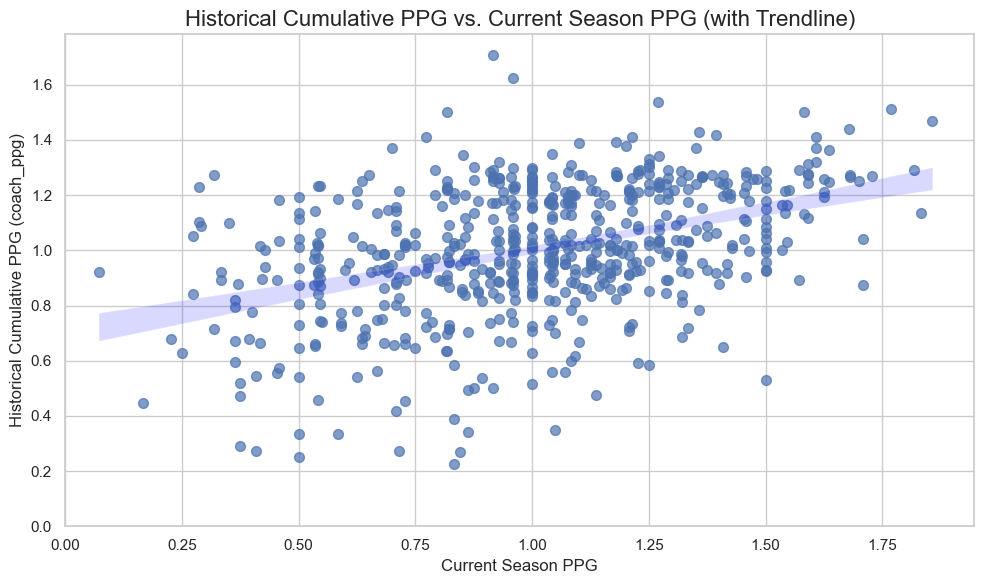

In [51]:
sns.set_theme(style="whitegrid")

# Create the scatter plot with a regression line using regplot
plt.figure(figsize=(10, 6))  # Adjust figure size as needed

# Using regplot combines scatter plot and linear regression line.
# Plotting current season PPG (x-axis) against historical cumulative PPG (coach_ppg, y-axis)
reg_plot = sns.regplot(
    data=df_combined2_seasons,
    x='PPG',       # Current Season PPG
    y='coach_ppg', # Historical Cumulative PPG (coach_ppg)
    scatter_kws={'s': 50, 'alpha': 0.7},  # Customize the scatter points
    line_kws={'color': 'blue'}           # Customize the regression line color
    # ci=None  # Uncomment this line if you want to hide the confidence interval ribbon
)

# Add informative title and labels
plt.title('Historical Cumulative PPG vs. Current Season PPG (with Trendline)', fontsize=16)
plt.xlabel('Current Season PPG', fontsize=12)
plt.ylabel('Historical Cumulative PPG (coach_ppg)', fontsize=12)

# Optionally, set axis limits to start at 0 (often makes sense for these metrics)
plt.xlim(left=0)
plt.ylim(bottom=0)

# Adjust layout to prevent overlap and display plot neatly
plt.tight_layout()
plt.show()

In [52]:
df_combined2_seasons.to_excel("df_combined2_seasons.xlsx", index=False)


In [53]:
df_combined2_seasons = df_combined2_seasons.dropna(thresh=df_combined2_seasons.shape[1] - 3)


In [54]:
df_combined2_seasons['coach_ppg'] = df_combined2_seasons['coach_ppg'].fillna(1)
df_combined2_seasons.isnull().sum()

/var/folders/nr/252791g92619jw78hvgkc57h0000gn/T/ipykernel_94393/3912904209.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_combined2_seasons['coach_ppg'] = df_combined2_seasons['coach_ppg'].fillna(1)


Rk                  0
PPG                 0
Season              0
tenure              0
Team                0
Category            0
Rank                0
Latitude            0
coach_ppg           0
GP                  0
G                   0
A                   0
PIM                 0
Shots               0
+/-                 0
power_play_goals    0
SHG                 0
GWG                 0
Blk                 0
FOW                 0
FOL                 0
GA                  0
Sv                  0
SO                  0
Min_Decimal         0
dtype: int64

At this point we are ready to start predicting

In [55]:
df_combined2_seasons['coach_ppg'] = df_combined2_seasons['coach_ppg'].replace(np.inf, 1)

/var/folders/nr/252791g92619jw78hvgkc57h0000gn/T/ipykernel_94393/3183006008.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_combined2_seasons['coach_ppg'] = df_combined2_seasons['coach_ppg'].replace(np.inf, 1)


In [66]:
df_combined2_seasons.to_excel("final_dataset.xlsx", index=False)

In [57]:
train = df_combined2_seasons[
    (df_combined2_seasons['Season'] >= 2013) & (df_combined2_seasons['Season'] <= 2021)
    ].copy()
test  = df_combined2_seasons[df_combined2_seasons['Season'].isin([2022, 2023])].copy()

# Pull out the dependent variable 'PPG'
y_train = train['PPG']
y_test  = test['PPG']

# Drop the target and ID columns from the feature sets
drop_cols = ['PPG', 'Rk', 'Team']
X_train = train.drop(columns=drop_cols)
X_test  = test.drop(columns=drop_cols)



AdaBoost

# Define the base estimator (DecisionTreeRegressor) without preset parameters so they can be tuned
base_tree = DecisionTreeRegressor()

# Instantiate the AdaBoost regressor with the base estimator
ada = AdaBoostRegressor(base_estimator=base_tree, random_state=42)

# Specify a parameter grid for RandomizedSearchCV including parameters for both AdaBoost and its base estimator
param_distributions = {
    'n_estimators': [50, 100, 150, 200, 250, 300],
    'learning_rate': [0.5, 1, 1.5, 2, 3],
    'base_estimator__max_depth': [1, 3, 5, 7, 9, 11],
    'base_estimator__min_samples_split': [2, 5, 10, 15, 20]
}

# Set up the RandomizedSearchCV with 5-fold CV and MAE as the scoring metric (using neg_mean_absolute_error)
random_search = RandomizedSearchCV(
    estimator=ada,
    param_distributions=param_distributions,
    n_iter=250,
    scoring='neg_mean_absolute_error',
    cv=5,
    random_state=42,
    n_jobs=-1
)


# Execute the random search on the training data
random_search.fit(X_train, y_train)
best_model = random_search.best_estimator_
print("Best Parameters:", random_search.best_params_)

Best Parameters: {'n_estimators': 250, 'learning_rate': 2, 'base_estimator__min_samples_split': 5, 'base_estimator__max_depth': 9}
Mean Absolute Error (Test): 0.09617852784352295
R² Score (Test): 0.83839724733212

# Evaluate the tuned model on the test set using MAE and R-squared
y_pred = best_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (Test):", mae)
print("R² Score (Test):", r2)


rf_model = RandomForestRegressor(random_state=42)

# Define the parameter grid to search
param_distributions_rf = {
    'n_estimators': [50, 100, 150, 200, 250, 300],
    'max_depth': [None, 10, 20, 30, 40, 50],
    'max_features': ['auto', 'sqrt', 'log2'],
    'min_samples_split': [2, 3, 5, 7, 10],
    'min_samples_leaf': [1, 2, 3, 4],
    'bootstrap': [True, False]
}

# Set up the RandomizedSearchCV object with 5-fold cross validation
rf_random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_distributions_rf,
    n_iter=250,
    scoring='neg_mean_absolute_error',
    cv=5,
    random_state=42,
    n_jobs=-1
)

# Execute the random search on the training data
rf_random_search.fit(X_train, y_train)
best_rf_model = rf_random_search.best_estimator_
print("Best Random Forest Parameters:", rf_random_search.best_params_)


# Evaluate the tuned Random Forest model on the test set
y_pred_rf = best_rf_model.predict(X_test)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Mean Absolute Error (Test):", mae_rf)
print("Random Forest R² Score (Test):", r2_rf)


Best Random Forest Parameters: {'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'auto', 'max_depth': 20, 'bootstrap': True}
Random Forest Mean Absolute Error (Test): 0.09753810867209764
Random Forest R² Score (Test): 0.8412516350557371

In [58]:
ada_best = AdaBoostRegressor(
    base_estimator=DecisionTreeRegressor(max_depth=9, min_samples_split=5, random_state=42),
    n_estimators=250,
    learning_rate=2,
    random_state=42
)
ada_best.fit(X_train, y_train)
y_pred_ada = ada_best.predict(X_test)
mae_ada = mean_absolute_error(y_test, y_pred_ada)
r2_ada = r2_score(y_test, y_pred_ada)

print("AdaBoost Mean Absolute Error (Test):", mae_ada)
print("AdaBoost R² Score (Test):", r2_ada)

AdaBoost Mean Absolute Error (Test): 0.09617852784352295
AdaBoost R² Score (Test): 0.83839724733212


In [59]:
rf_best = RandomForestRegressor(
    n_estimators=150,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='auto',
    max_depth=20,
    bootstrap=True,
    random_state=42
)
rf_best.fit(X_train, y_train)
y_pred_rf = rf_best.predict(X_test)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Mean Absolute Error (Test):", mae_rf)
print("Random Forest R² Score (Test):", r2_rf)

Random Forest Mean Absolute Error (Test): 0.09753810867209764
Random Forest R² Score (Test): 0.8412516350557371


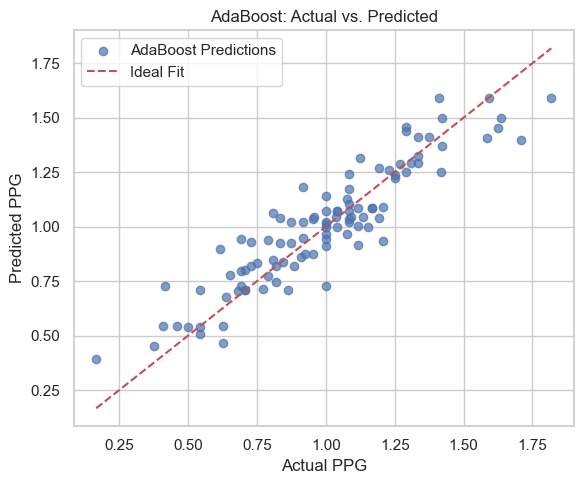

In [60]:
all_values = np.concatenate([y_test, y_pred_ada, y_pred_rf])
min_val, max_val = all_values.min(), all_values.max()

# AdaBoost plot
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_ada, alpha=0.7, label='AdaBoost Predictions', color='b')
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Fit')
plt.xlabel("Actual PPG")
plt.ylabel("Predicted PPG")
plt.title("AdaBoost: Actual vs. Predicted")
plt.legend()
plt.tight_layout()
plt.show()

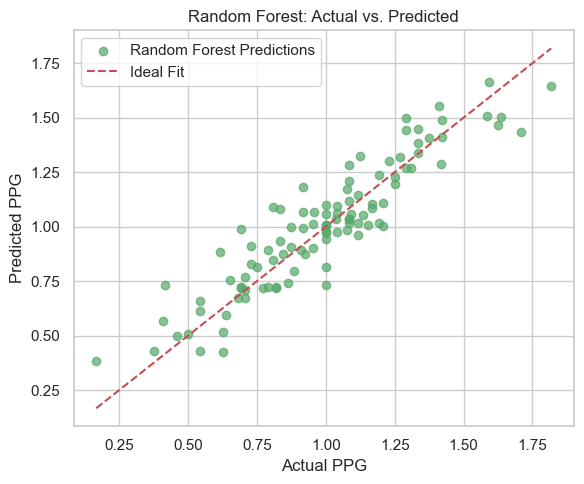

In [61]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_rf, alpha=0.7, label='Random Forest Predictions', color='g')
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Fit')
plt.xlabel("Actual PPG")
plt.ylabel("Predicted PPG")
plt.title("Random Forest: Actual vs. Predicted")
plt.legend()
plt.tight_layout()
plt.show()

AdaBoost Feature Importances:
+/-                 0.686364
GWG                 0.115109
A                   0.029762
Shots               0.018886
coach_ppg           0.016218
Blk                 0.015285
GA                  0.012495
GP                  0.012126
FOL                 0.011653
Rank                0.010581
Latitude            0.010166
PIM                 0.009507
tenure              0.008057
FOW                 0.007295
power_play_goals    0.005529
G                   0.005270
Sv                  0.005011
Min_Decimal         0.004895
Season              0.004842
SO                  0.004778
SHG                 0.004446
Category            0.001725
dtype: float64


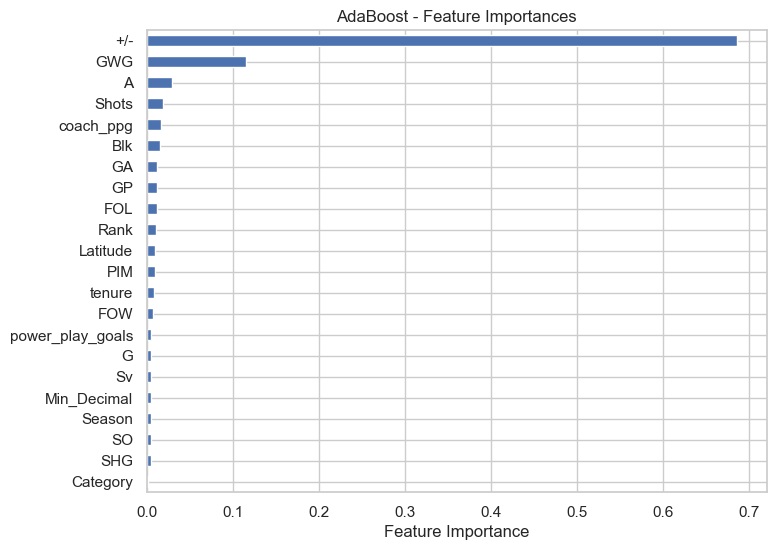

In [62]:

feature_importances = pd.Series(ada_best.feature_importances_, index=X_train.columns)

# Sort the importances in descending order
sorted_importances = feature_importances.sort_values(ascending=False)
print("AdaBoost Feature Importances:")
print(sorted_importances)

# Optionally, visualize the feature importances using a horizontal bar chart
plt.figure(figsize=(8, 6))
sorted_importances.plot(kind='barh')
plt.xlabel("Feature Importance")
plt.title("AdaBoost - Feature Importances")
plt.gca().invert_yaxis()  # highest importance at the top
plt.show()


Random Forest Permutation Importances (mean over 10 repeats):
+/-                 1.369291
GWG                 0.039002
A                   0.005497
Rank                0.004422
power_play_goals    0.003679
PIM                 0.003203
FOL                 0.001805
Category            0.001116
Blk                 0.001028
GA                  0.000599
tenure              0.000438
SO                  0.000307
G                   0.000015
Season              0.000000
coach_ppg          -0.000110
Shots              -0.000172
SHG                -0.000203
Min_Decimal        -0.000420
FOW                -0.000557
Sv                 -0.000774
GP                 -0.001944
Latitude           -0.004131
dtype: float64


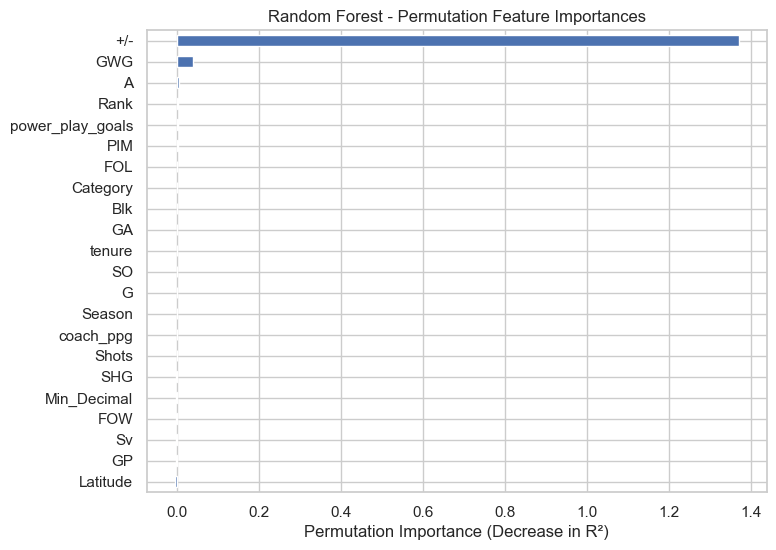

In [63]:
# --- Permutation Importance ---
# Calculate permutation importance on the test set (using r² as scoring)
perm_importance = permutation_importance(
    rf_best, X_test, y_test, scoring='r2', n_repeats=10, random_state=42
)

# Create a Series for permutation importance mean values
perm_importances = pd.Series(perm_importance.importances_mean, index=X_test.columns)
perm_importances = perm_importances.sort_values(ascending=False)
print("Random Forest Permutation Importances (mean over 10 repeats):")
print(perm_importances)

# Plot permutation importance
plt.figure(figsize=(8, 6))
perm_importances.plot(kind='barh')
plt.xlabel("Permutation Importance (Decrease in R²)")
plt.title("Random Forest - Permutation Feature Importances")
plt.gca().invert_yaxis()  # Highest importance at the top
plt.show()

Random Forest Mean Decrease in Impurity (MDI) Importances:
+/-                 0.803106
GWG                 0.042043
coach_ppg           0.014908
Shots               0.014840
GP                  0.014521
A                   0.013226
Blk                 0.011141
GA                  0.009911
Rank                0.009861
PIM                 0.009517
FOL                 0.008960
power_play_goals    0.006794
Latitude            0.006110
tenure              0.005649
FOW                 0.005362
G                   0.004497
Min_Decimal         0.004292
Sv                  0.003903
Season              0.003894
SO                  0.003581
SHG                 0.002542
Category            0.001343
dtype: float64


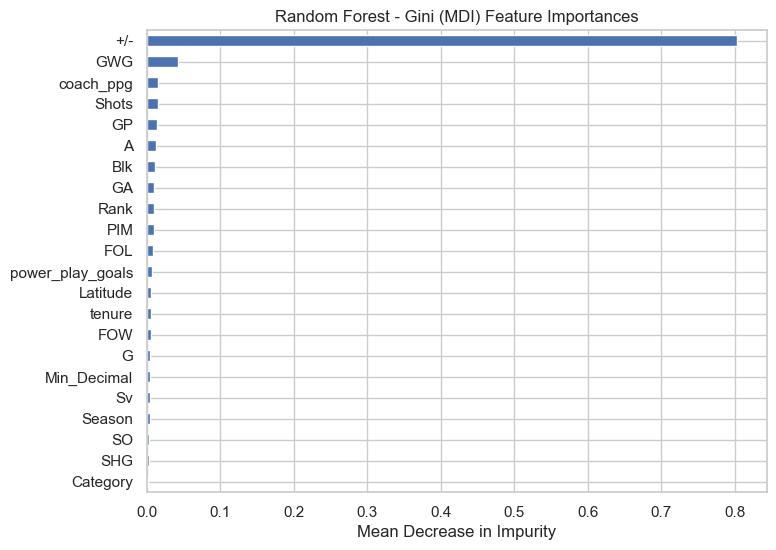

In [64]:
# --- Mean Decrease in Impurity (Gini Importance) ---
mdi_importances = pd.Series(rf_best.feature_importances_, index=X_train.columns)
mdi_importances = mdi_importances.sort_values(ascending=False)
print("Random Forest Mean Decrease in Impurity (MDI) Importances:")
print(mdi_importances)

# Plot MDI feature importances
plt.figure(figsize=(8, 6))
mdi_importances.plot(kind='barh')
plt.xlabel("Mean Decrease in Impurity")
plt.title("Random Forest - Gini (MDI) Feature Importances")
plt.gca().invert_yaxis()  # Highest importance at the top
plt.show()


In [65]:
# Scale the data (if not already scaled)
scaler_nn = StandardScaler()
X_train_nn = scaler_nn.fit_transform(X_train)
X_test_nn  = scaler_nn.transform(X_test)

# Build the MLP model
model = Sequential()
model.add(Dense(128, activation='relu', input_shape=(X_train_nn.shape[1],)))
model.add(Dropout(0.3))  # Helps prevent overfitting on small datasets
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='linear'))  # Linear activation for regression

# Compile the model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mean_absolute_error',  # MAE as the loss function since performance is measured with MAE
    metrics=['mean_absolute_error']
)

# Set up callbacks for early stopping and learning rate reduction
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=10,
    min_lr=1e-6
)

# Train the model. Using validation_split since the dataset is small.
history = model.fit(
    X_train_nn,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=16,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# Evaluate on the test set
y_pred_nn = model.predict(X_test_nn).flatten()  # flatten in case of (n,1) shape
mae_nn = mean_absolute_error(y_test, y_pred_nn)
r2_nn = r2_score(y_test, y_pred_nn)

print("Neural Network Mean Absolute Error (Test):", mae_nn)
print("Neural Network R² Score (Test):", r2_nn)

NameError: name 'Sequential' is not defined